<a href="https://colab.research.google.com/github/Aasthahcs05/Sentiment_Analysis_using_BERT/blob/main/Sentiment_Analysis_using_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q transformers datasets evaluate accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.6 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

import evaluate

In [4]:
!pip install -q -U "datasets==3.6.0" "huggingface_hub==0.30.2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.4/481.4 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 9.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.30.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.30.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.30.2 which

In [5]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [6]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [7]:
print(dataset["train"][0])

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [8]:
print(dataset["train"][1])

{'text': '"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn\'t matter what one\'s political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn\'t true. I\'ve seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? Nowhere, because they don\'t exist. The same goes for those crappy cable shows: schlongs swinging in the breeze but not a clitoris in sight. And those pretentious indie movies like The Brown Bunny, in which we\'re treated to the site of Vincent Gallo\'s throbbing johnson, but not a trace of pink visible on Chloe Sevigny. Before crying (or implying) "double-standard" in matters of nudity, the mentally obtuse should take into account one unavoidably obvious anatomical difference between men and women: there are no genitals on display when actresses appears nude, 

In [9]:
print("Training samples:", len(dataset["train"]))
print("Testing samples:", len(dataset["test"]))

Training samples: 25000
Testing samples: 25000


In [10]:
print(dataset["train"].features["label"])

ClassLabel(names=['neg', 'pos'])


In [11]:
train_labels = dataset["train"]["label"]

negative = train_labels.count(0)
positive = train_labels.count(1)

print("Negative reviews:", negative)
print("Positive reviews:", positive)

Negative reviews: 12500
Positive reviews: 12500


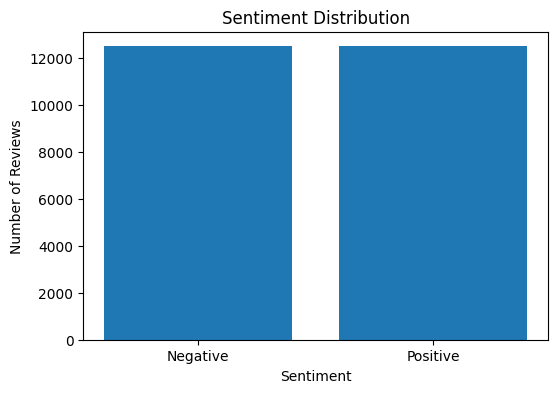

In [12]:
labels = ["Negative", "Positive"]
counts = [negative, positive]

plt.figure(figsize=(6, 4))
plt.bar(labels, counts)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [13]:
review_lengths = [len(text.split()) for text in dataset["train"]["text"]]

print("Average words:", np.mean(review_lengths))
print("Minimum words:", np.min(review_lengths))
print("Maximum words:", np.max(review_lengths))

Average words: 233.7872
Minimum words: 10
Maximum words: 2470


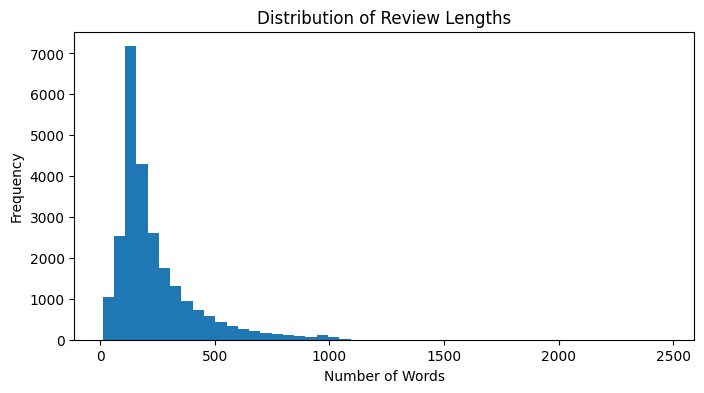

In [14]:
plt.figure(figsize=(8, 4))
plt.hist(review_lengths, bins=50)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [15]:
split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
validation_dataset = split_dataset["test"]
test_dataset = dataset["test"]

print("Training:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Testing:", len(test_dataset))

Training: 20000
Validation: 5000
Testing: 25000


In [16]:
model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully


In [17]:
text = "This movie was absolutely amazing!"

tokens = tokenizer.tokenize(text)

print(tokens)

['this', 'movie', 'was', 'absolutely', 'amazing', '!']


In [18]:
encoded = tokenizer(text)

print(encoded)

{'input_ids': [101, 2023, 3185, 2001, 7078, 6429, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [19]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [20]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_validation = validation_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [21]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_validation = validation_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

In [22]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("BERT model loaded successfully")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully


In [23]:
accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")

In [24]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )

    precision = precision_metric.compute(
        predictions=predictions,
        references=labels,
        average="binary"
    )

    recall = recall_metric.compute(
        predictions=predictions,
        references=labels,
        average="binary"
    )

    f1 = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="binary"
    )

    return {
        "accuracy": accuracy["accuracy"],
        "precision": precision["precision"],
        "recall": recall["recall"],
        "f1": f1["f1"]
    }

In [25]:
training_args = TrainingArguments(
    output_dir="./bert_sentiment_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

In [26]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Trainer created successfully")

Trainer created successfully


In [27]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.330039,0.329291,0.882400,0.889837,0.873504,0.881595
2,0.232005,0.418547,0.885200,0.880615,0.891860,0.886201


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [28]:
validation_results = trainer.evaluate(
    tokenized_validation
)

print(validation_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.232005,0.418547,2,0.885200,0.880615,0.891860,0.886201


{'eval_loss': 0.418547123670578, 'eval_accuracy': 0.8852, 'eval_precision': 0.8806146572104019, 'eval_recall': 0.8918595371109338, 'eval_f1': 0.8862014274385408}


In [29]:
test_results = trainer.evaluate(
    tokenized_test
)

print(test_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.232005,0.412603,2,0.889080,0.879339,0.901920,0.890486


{'eval_loss': 0.41260290145874023, 'eval_accuracy': 0.88908, 'eval_precision': 0.879338585133765, 'eval_recall': 0.90192, 'eval_f1': 0.8904861577346866}


In [30]:
print("Final Test Results")
print("------------------")

print("Accuracy :", round(test_results["eval_accuracy"], 4))
print("Precision:", round(test_results["eval_precision"], 4))
print("Recall   :", round(test_results["eval_recall"], 4))
print("F1 Score :", round(test_results["eval_f1"], 4))

Final Test Results
------------------
Accuracy : 0.8891
Precision: 0.8793
Recall   : 0.9019
F1 Score : 0.8905


In [31]:
predictions = trainer.predict(tokenized_test)

predicted_labels = np.argmax(
    predictions.predictions,
    axis=1
)

actual_labels = np.array(test_dataset["label"])

In [32]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    actual_labels,
    predicted_labels
)

print(cm)

[[10953  1547]
 [ 1226 11274]]


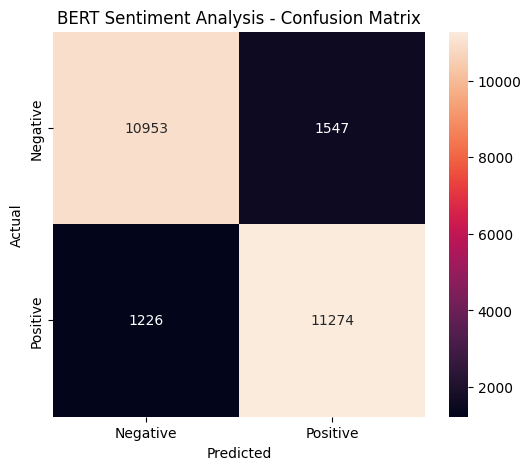

In [33]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BERT Sentiment Analysis - Confusion Matrix")

plt.show()

In [34]:
from sklearn.metrics import classification_report

report = classification_report(
    actual_labels,
    predicted_labels,
    target_names=["Negative", "Positive"]
)

print(report)

              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89     12500
    Positive       0.88      0.90      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000



In [35]:
history = trainer.state.log_history

train_loss = []
eval_loss = []
epochs = []

for item in history:

    if "loss" in item:
        train_loss.append(item["loss"])

    if "eval_loss" in item:
        eval_loss.append(item["eval_loss"])

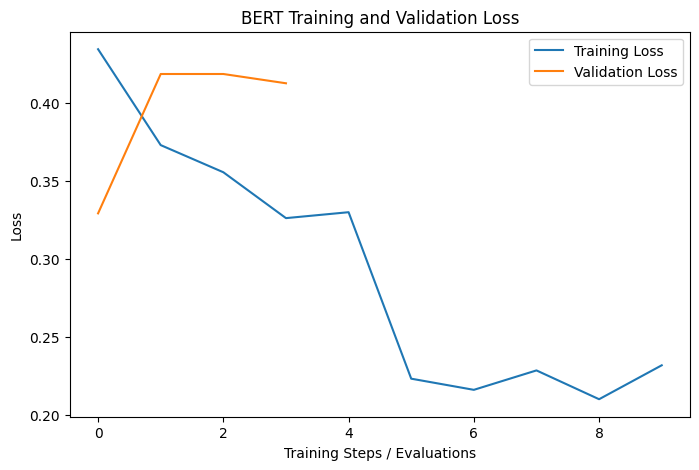

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(train_loss, label="Training Loss")
plt.plot(eval_loss, label="Validation Loss")

plt.xlabel("Training Steps / Evaluations")
plt.ylabel("Loss")
plt.title("BERT Training and Validation Loss")

plt.legend()
plt.show()

In [38]:
import torch

In [37]:
def predict_sentiment(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    outputs = model(**inputs)

    probabilities = outputs.logits.softmax(dim=-1)

    prediction = torch.argmax(
        probabilities,
        dim=-1
    ).item()

    confidence = probabilities[0][prediction].item()

    sentiment = "Positive" if prediction == 1 else "Negative"

    return sentiment, confidence

In [39]:
reviews = [
    "This movie was absolutely fantastic and I loved every minute of it.",
    "The movie was boring, slow and extremely disappointing.",
    "The acting was excellent and the story was very engaging.",
    "I regret watching this movie. It was terrible."
]

for review in reviews:

    sentiment, confidence = predict_sentiment(review)

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("-" * 70)

Review: This movie was absolutely fantastic and I loved every minute of it.
Sentiment: Positive
Confidence: 99.84 %
----------------------------------------------------------------------
Review: The movie was boring, slow and extremely disappointing.
Sentiment: Negative
Confidence: 99.89 %
----------------------------------------------------------------------
Review: The acting was excellent and the story was very engaging.
Sentiment: Positive
Confidence: 99.73 %
----------------------------------------------------------------------
Review: I regret watching this movie. It was terrible.
Sentiment: Negative
Confidence: 99.85 %
----------------------------------------------------------------------


In [41]:
model.save_pretrained("./bert-sentiment-model")
tokenizer.save_pretrained("./bert-sentiment-model")

print("Model saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully.


In [42]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

saved_model = AutoModelForSequenceClassification.from_pretrained(
    "./bert-sentiment-model"
)

saved_tokenizer = AutoTokenizer.from_pretrained(
    "./bert-sentiment-model"
)

print("Saved model loaded successfully.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Saved model loaded successfully.


In [43]:
results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        test_results["eval_accuracy"],
        test_results["eval_precision"],
        test_results["eval_recall"],
        test_results["eval_f1"]
    ]
})

results_df

,Metric,Score
0,Accuracy,0.889080
1,Precision,0.879339
2,Recall,0.901920
3,F1 Score,0.890486
